In [1]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import *

In [2]:
data = pd.read_csv('../Data/temp_training.csv')

/var/folders/22/3z4yr_bd5ds4d1g7ph9nprs80000gn/T/ipykernel_53756/3943470689.py:1: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv('../Data/temp_training.csv')


In [3]:
data_stats = pickle.load(open('../Files/data_statistics.pkl', 'rb'))
print(data_stats.keys())
data_stats['asset_cols']['description']

dict_keys(['identifier_and_date_cols', 'firm_characteristics_cols', 'asset_cols', 'equity_capital_cols', 'debt_cols', 'revenue_and_expenses_cols', 'profitability_cols', 'liquidity_and_cashflows_cols', 'ops_efficiency_cols'])


,asst_intang_fixed,asst_tang_fixed,asst_fixed_fin,asst_current,AR,cash_and_equiv,asst_tot,goodwill
count,1.023390e+06,1.023449e+06,1.023315e+06,1.023551e+06,1.023540e+06,1.023535e+06,1.023552e+06,1.023531e+06
mean,4.684047e+05,3.411074e+06,1.171699e+06,5.957970e+06,3.360637e+06,4.751146e+05,1.111351e+07,1.612102e+06
std,1.486886e+07,1.293634e+08,2.875413e+07,5.419817e+07,3.994736e+07,9.391475e+06,1.799274e+08,2.193186e+07
min,-3.442959e+06,-1.711468e+06,-2.490262e+06,0.000000e+00,-2.782518e+06,-2.584593e+07,1.500000e+06,-5.435823e+09
25%,2.620000e+02,6.663100e+04,0.000000e+00,1.072830e+06,2.340728e+05,6.223000e+03,2.170073e+06,1.016930e+05
50%,7.975000e+03,5.958990e+05,1.378000e+03,2.040524e+06,8.916955e+05,4.964700e+04,3.458428e+06,4.207020e+05
75%,7.515675e+04,2.064874e+06,7.188100e+04,4.135408e+06,2.092540e+06,2.628755e+05,6.975953e+06,1.074216e+06
max,3.708467e+09,5.822144e+10,8.529187e+09,1.479057e+10,1.101077e+10,5.519622e+09,7.164463e+10,5.632980e+09


In [4]:
data_stats['asset_cols']['null_information'] 

,feature,null_count
0,asst_intang_fixed,162
1,asst_tang_fixed,103
2,asst_fixed_fin,237
3,asst_current,1
4,AR,12
5,cash_and_equiv,17
6,asst_tot,0
7,goodwill,21


In [ ]:
df_filt = df_filt.sort_values(by='default')
df_filt

,asst_intang_fixed,asst_tang_fixed,asst_fixed_fin,asst_current,AR,cash_and_equiv,asst_tot,goodwill,default,data_type
0,67537.0,1137566.0,1908.0,733496.0,283013.0,2083.0,1946940.0,157436.0,0,oot
551094,290964.0,187651.0,0.0,5740454.0,4207530.0,27910.0,6232192.0,1687575.0,0,train
551095,1096126.0,568155.0,5000.0,11661633.0,7747969.0,210189.0,13362429.0,1404927.0,0,test
551096,811527.0,441066.0,109600.0,11727714.0,7124358.0,339738.0,13218027.0,2780354.0,0,oot
551097,622752.0,345725.0,509796.0,8779593.0,6091290.0,27730.0,10268839.0,1264613.0,0,train
...,...,...,...,...,...,...,...,...,...,...
779969,43332.0,1895410.0,0.0,2983289.0,1365722.0,982200.0,4924247.0,1032208.0,1,train
789143,57378.0,8907033.0,5995236.0,16449290.0,13587884.0,1774281.0,31591518.0,5387061.0,1,train
779971,0.0,32357.0,0.0,1972702.0,637564.0,19883.0,2035540.0,224410.0,1,train
779958,561.0,5879936.0,71.0,1274746.0,789.0,147132.0,7159108.0,-70220.0,1,train


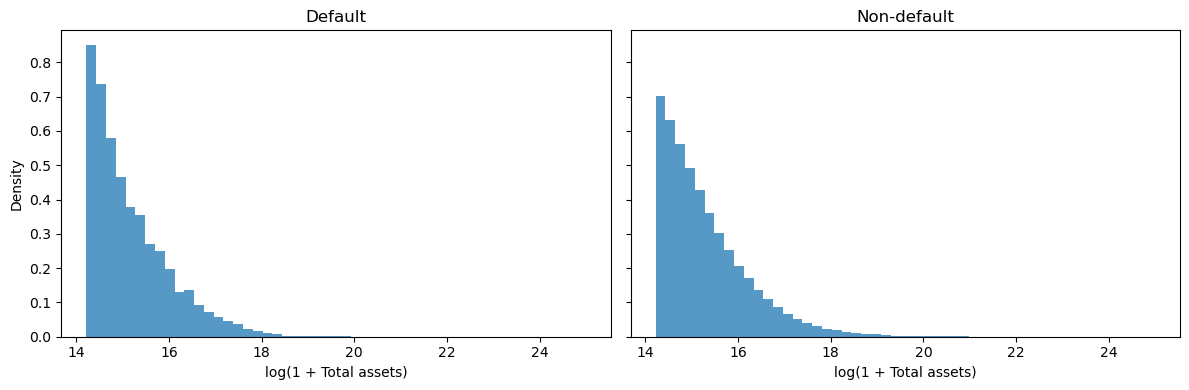

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)

bins = np.histogram_bin_edges(
    np.log1p(df_filt["asst_tot"].dropna()), bins=51
)
for ax, label in zip(axes, [1, 0]):
    values = np.log1p(
        df_filt.loc[df_filt["default"] == label, "asst_tot"].dropna()
    )
    ax.hist(values, bins=bins, density=True, alpha=0.75)
    ax.set_title("Default" if label == 1 else "Non-default")
    ax.set_xlabel("log(1 + Total assets)")

axes[0].set_ylabel("Density")
plt.tight_layout()
plt.show()

In [ ]:
df_filt['AR'].isna().sum()

np.int64(12)

In [ ]:
temp = df_filt[['AR','default','data_type']]
temp['feat'] = np.log1p(temp['AR'])
# plt.hist(temp['feat'])

/opt/homebrew/Caskroom/miniconda/base/envs/nlp/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/homebrew/Caskroom/miniconda/base/envs/nlp/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)
/var/folders/22/3z4yr_bd5ds4d1g7ph9nprs80000gn/T/ipykernel_40092/1395079036.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  temp['feat'] = np.log1p(temp['AR'])


/opt/homebrew/Caskroom/miniconda/base/envs/nlp/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/homebrew/Caskroom/miniconda/base/envs/nlp/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)


ValueError: supplied range of [-inf, 22.96945918694506] is not finite

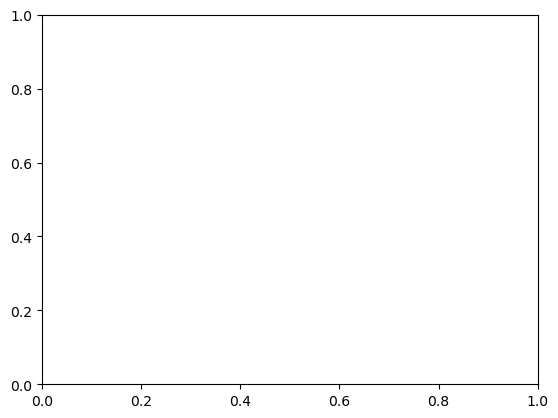

In [ ]:
plt.hist(np.log1p(df_filt.query('default == 0')['AR']))
plt.hist(np.log1p(df_filt.query('default == 1')['AR']))